# Emometer 3: four emotions across four stories

`test2.ipynb` found 5 SAE features for one emotion and followed them through one story. This notebook does the same for **four emotions at once** (joy, sadness, anger and fear, the four that EmoLex also has) and runs them over **four stories of different lengths**.

- **Model and SAEs:** as in `test.ipynb` and `test2.ipynb`: `llama3.1-8b` (Llama 3.1 8B base) with the Llama Scope 32k residual-stream SAEs.
- **Features:** picked by `test2.ipynb`'s method (search layers 12–27 with clearly emotional probe texts, keep labels that name the emotion, drop anything that fires on a neutral text, take the top 5). That makes 20 features, 5 per emotion.
- **Per story, two figures:** the SAE arcs (each emotion's 5 features added up, as in `test2.ipynb` Figure 2) and the EmoLex arcs (share of words tagged with each emotion). Both use 100-word windows. Each emotion keeps the same colour in every figure.
- **x-axis:** position as a percentage of the story, so stories of different lengths line up.

**Requests:** instead of one request per feature per chunk, this notebook asks Neuronpedia's `/api/activation/source` for *every* active feature in a layer at once, which matches `/api/activation/new` to within 0.001. The 20 features sit in 9 layers, so each chunk costs 9 requests. That endpoint has its own budget (25,000) rather than the 1,000-per-hour limit. Responses are cached in `.layer_cache/`, keeping only the features used here.

The figures are saved to `figures/test3/figure1.png` to `figure8.png`, two per story, shortest story first.

In [1]:
import bisect
import contextlib
import hashlib
import io
import json
import math
import os
import re
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import requests
from dotenv import load_dotenv
from neuronpedia.requests.activation_request import ActivationRequest
from neuronpedia.requests.base_request import NPRateLimitError

load_dotenv()

MODEL_ID = "llama3.1-8b"
SOURCE_SET = "llamascope-res-32k"
LAYERS = [f"{layer}-{SOURCE_SET}" for layer in range(12, 28)]  # middle and middle-later layers of 32

EMOTIONS = ["joy", "sadness", "anger", "fear"]  # all four have probe texts below and an EmoLex category
N_FEATURES = 5
DENSITY_MAX = 0.01       # skip features active on more than 1% of all tokens
NEUTRAL_MAX = 0.10       # drop a feature whose activation on the neutral text exceeds 10% of its max

# Four public-domain stories from Project Gutenberg, shortest first. Each is cut to the story itself:
# from `start` to the end of `end`, dropping the title page, epigraphs, footnotes and "THE END".
STORIES = [
    {"id": 7256, "title": "The Gift of the Magi", "author": "O. Henry",
     "start": "One dollar and eighty-seven cents.", "end": "They are the magi."},
    {"id": 375, "title": "An Occurrence at Owl Creek Bridge", "author": "Ambrose Bierce",
     "start": "A man stood upon a railroad bridge", "end": "beneath the timbers of the Owl Creek bridge."},
    {"id": 932, "title": "The Fall of the House of Usher", "author": "Edgar Allan Poe",
     "start": "During the whole of a dull, dark", "end": 'closed sullenly and silently over the fragments of the "House of Usher".'},
    {"id": 41, "title": "The Legend of Sleepy Hollow", "author": "Washington Irving",
     "start": "In the bosom of one", "end": "I don’t believe one-half of it myself.”"},
]
STORY_DIR = Path("stories")
WINDOW_WORDS = 100
FIG_DATE = "Nov 13, 2026"

# Clearly emotional texts used to find the features. Several per emotion, so a feature that only
# reacts to one word or one situation scores lower than one that fires on all of them.
PROBES = {
    "joy": [
        "We won! Everyone was laughing and hugging, and I was so happy I could have danced all night.",
        "When she opened the door and saw all her friends shouting 'Surprise!', her face lit up with pure joy. It was the best birthday of her life.",
        "The baby giggled, and her grandfather beamed with delight. Nothing in the world could have made him happier than that little laugh.",
        "I got the job! I called my mom, and we were both cheering and crying happy tears. What a wonderful, glorious day.",
    ],
    "sadness": [
        "After the funeral the house felt empty. She sat on his side of the bed and cried until there were no tears left.",
        "He read the letter again. She wasn't coming back. He felt a heavy, hollow sorrow settle in his chest.",
        "The old dog didn't wake up this morning. The children wept quietly in the yard, too heartbroken to speak.",
        "I miss you so much. Every day without you is gray and lonely, and the grief never really goes away.",
    ],
    "anger": [
        "He slammed his fist on the table and shouted, 'How dare you lie to me!' His face was red with rage.",
        "She was furious. They had cheated her out of her pay, and she wanted to scream at every one of them.",
        "I am so angry I can't think straight. You broke your promise again, and I'm sick of your excuses!",
        "The crowd roared in outrage, hurling insults and shaking their fists at the corrupt officials.",
    ],
    "fear": [
        "Something was breathing in the dark behind her. She froze, terrified, her heart pounding in her ears.",
        "He was so scared he couldn't move. The footsteps came closer, and he knew whoever it was would find him.",
        "The children screamed in terror as the house shook and the walls began to crack.",
        "I'm afraid. I keep hearing noises at night, and I'm too frightened to open the door.",
    ],
}
NEUTRAL = (
    "The train leaves the central station at nine fifteen and arrives in the city just after eleven. "
    "Passengers can buy tickets at the counter or from the machines near the main entrance. The second "
    "carriage has tables and power outlets."
)

# A feature is kept only if its autointerp label matches INCLUDE and not EXCLUDE (whole words, any case).
_OTHER_TOPICS = r"histor\w*|politic\w*|legal|religio\w*|sport\w*"
INCLUDE = {
    "joy": r"happ\w*|joy\w*|delight\w*|cheer\w*|celebrat\w*|excite\w*|excitement|elat\w*|glad\w*|enjoy\w*|laugh\w*|bliss\w*|euphori\w*|jubila\w*",
    "sadness": r"sad\w*|grie\w*|mourn\w*|sorrow\w*|melanchol\w*|despair\w*|lonel\w*|heartbr\w*|weep\w*|crying|tears",
    "anger": r"anger|angry|rage|fury|furious|hostil\w*|resent\w*|frustrat\w*|annoy\w*|irritat\w*|outrage\w*",
    "fear": r"fear\w*|afraid|terror|terrif\w*|scare\w*|dread\w*|horror|fright\w*|panic\w*",
}
_OPPOSITE = {"joy": r"distress|negative", "sadness": "positive", "anger": "positive", "fear": "positive"}
# A label is excluded if it also names another emotion, the opposite valence or an unrelated topic.
EXCLUDE = {
    emotion: "|".join([p for other, p in INCLUDE.items() if other != emotion] + [_OPPOSITE[emotion], _OTHER_TOPICS])
    for emotion in INCLUDE
}

# Story requests, as in test.ipynb
MAX_CHUNK_CHARS = 900
MIN_CHUNK_CHARS = 60
MAX_CONCURRENT = 8
RETRIES = 4
TIMEOUT = 60
RATE_LIMIT_PER_HOUR = 1000
RATE_LIMIT_PAUSE = 300
WAIT_FOR_RATE_LIMIT = True
CACHE_DIR = Path(".activation_cache")   # shared with test.ipynb
SEARCH_CACHE_DIR = Path(".search_cache")

# One colour per emotion, the same in every figure. Checked as a set for colour-blind separation; joy/yellow
# and fear-green vs anger-red sit near the floor, so every line also carries a direct text label.
EMOTION_COLORS = {"joy": "#eda100", "sadness": "#2a78d6", "anger": "#e34948", "fear": "#008300"}
LAYER_CACHE_DIR = Path(".layer_cache")
INK, MUTED, RULE = "#0b0b0b", "#52514e", "#e4e3df"

In [2]:
# ---------- Neuronpedia: feature search ----------

def search_layer(text: str, layer: str) -> dict:
    """Top 99 features in one layer by peak activation on `text` (Neuronpedia's /api/search-all), cached on disk."""
    key = hashlib.sha256(f"{MODEL_ID}|{layer}|{DENSITY_MAX}|{text}".encode()).hexdigest()
    path = SEARCH_CACHE_DIR / f"{key}.json"
    if path.exists():
        return json.loads(path.read_text())
    payload = {
        "modelId": MODEL_ID, "sourceSet": SOURCE_SET, "text": text, "selectedLayers": [layer],
        "sortIndexes": [], "ignoreBos": True, "densityThreshold": DENSITY_MAX, "numResults": 99,
    }
    for attempt in range(RETRIES):
        resp = requests.post("https://www.neuronpedia.org/api/search-all", json=payload, timeout=300,
                             headers={"X-Api-Key": os.environ["NEURONPEDIA_API_KEY"]})
        if resp.status_code == 429:
            time.sleep(RATE_LIMIT_PAUSE)
            continue
        if resp.ok:
            break
        time.sleep(2 ** (attempt + 1))
    resp.raise_for_status()
    data = resp.json()
    # keep only what the notebook uses; the full response carries large per-feature histograms
    slim = {"tokens": data["tokens"], "result": [
        {"layer": r["layer"], "index": int(r["index"]), "maxValue": r["maxValue"], "maxValueIndex": r["maxValueIndex"],
         "maxActApprox": r["neuron"]["maxActApprox"], "density": r["neuron"]["frac_nonzero"],
         "label": (r["neuron"]["explanations"][0]["description"].strip() if r["neuron"]["explanations"] else "")}
        for r in data["result"]
    ]}
    SEARCH_CACHE_DIR.mkdir(exist_ok=True)
    path.write_text(json.dumps(slim))
    return slim


# ---------- Neuronpedia: activations (as in test.ipynb) ----------

@contextlib.contextmanager
def _quiet():
    # Neuronpedia's client prints a line per request. Process-wide, so only enter from the main thread.
    with contextlib.redirect_stdout(io.StringIO()):
        yield


def _chunks(text: str, max_chars: int = MAX_CHUNK_CHARS) -> list[tuple[str, str]]:
    """Split `text` into (chunk, following whitespace) pairs of at most ~max_chars, cutting after sentences."""
    parts = re.split(r"(\s+)", text.strip())
    words, seps = parts[0::2], parts[1::2] + [""]
    is_sentence_end = [bool(re.search(r"[.!?][\"'”’)\]]*$", w)) for w in words]
    chunks, start, length = [], 0, 0
    for i, word in enumerate(words):
        if length + len(word) > max_chars and i > start:
            ends = [j for j in range(start, i) if is_sentence_end[j]]
            cut = ends[-1] if ends else i - 1
            chunks.append(("".join(parts[2 * start : 2 * cut + 1]), seps[cut]))
            start = cut + 1
            length = len("".join(parts[2 * start : 2 * i]))
        length += len(word) + len(seps[i])
    chunks.append(("".join(parts[2 * start :]), ""))
    return chunks


class _ServerError(Exception):
    """Neuronpedia kept failing on a text (usually because it is too long)."""


_pause_lock = threading.Lock()
_paused_until = 0.0


def _wait_out_rate_limit(hit: bool = False) -> None:
    global _paused_until
    with _pause_lock:
        if hit and time.time() >= _paused_until:
            _paused_until = time.time() + RATE_LIMIT_PAUSE
            print(f"{time.strftime('%H:%M')} rate limited ({RATE_LIMIT_PER_HOUR} activation requests per hour); "
                  f"pausing {RATE_LIMIT_PAUSE // 60} min. Finished requests are cached.", file=sys.stderr)
        wait = _paused_until - time.time()
    if wait > 0:
        time.sleep(wait)


def _cache_path(source: str, index: int, text: str) -> Path:
    key = hashlib.sha256(f"{MODEL_ID}|{source}|{index}|{text}".encode()).hexdigest()
    return CACHE_DIR / key[:2] / f"{key}.json"


def _request(source: str, index: int, text: str) -> tuple[list[str], list[float]]:
    """Tokens of `text` and one feature's activation on each, from the disk cache or from Neuronpedia."""
    path = _cache_path(source, index, text)
    if path.exists():
        data = json.loads(path.read_text())
        return data["tokens"], data["values"]
    payload = {"feature": {"modelId": MODEL_ID, "layer": source, "index": str(index)}, "customText": text}
    failures = 0
    while True:
        _wait_out_rate_limit()
        try:
            result = ActivationRequest().send_request(method="POST", json=payload, uri="new", timeout=TIMEOUT)
            break
        except NPRateLimitError:
            if not WAIT_FOR_RATE_LIMIT:
                raise
            _wait_out_rate_limit(hit=True)
            continue
        except requests.HTTPError as e:
            if "Server error" not in str(e):
                raise
        except (requests.ConnectionError, requests.Timeout):
            pass
        failures += 1
        if failures == RETRIES:
            raise _ServerError(text)
        time.sleep(2**failures)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(f".{threading.get_ident()}.tmp")
    tmp.write_text(json.dumps({"tokens": result["tokens"], "values": result["values"]}))
    tmp.replace(path)
    return result["tokens"], result["values"]


def _chunk_activations(chunk: str, features: list[tuple[str, int]]) -> tuple[list[str], list[list[float]]]:
    """Tokens of one chunk and each feature's activations on them; splits the chunk if Neuronpedia keeps failing."""
    try:
        results = [_request(source, index, chunk) for source, index in features]
    except _ServerError:
        pieces = _chunks(chunk, len(chunk) // 2)
        if len(chunk) < 2 * MIN_CHUNK_CHARS or len(pieces) < 2:
            raise
        tokens, acts = [], [[] for _ in features]
        for piece, sep in pieces:
            piece_tokens, piece_acts = _chunk_activations(piece, features)
            tokens += piece_tokens + ([sep] if sep else [])
            for a, pa in zip(acts, piece_acts):
                a += pa + ([0.0] if sep else [])
        return tokens, acts
    return results[0][0], [values for _, values in results]


def feature_activations(text: str, features: list[tuple[str, int]]) -> tuple[list[str], list[list[float]]]:
    """Tokens of `text` and, for each feature, its activation on every token. Requests are cached."""
    chunks = _chunks(text)
    with _quiet(), ThreadPoolExecutor(MAX_CONCURRENT) as pool:
        results = list(pool.map(lambda c: _chunk_activations(c[0], features), chunks))
    tokens, acts = [], [[] for _ in features]
    for (chunk_tokens, chunk_acts), (_, sep) in zip(results, chunks):
        tokens += chunk_tokens + ([sep] if sep else [])
        for a, ca in zip(acts, chunk_acts):
            a += ca + ([0.0] if sep else [])
    return tokens, acts


# ---------- windows ----------

def word_windows(text: str, window_words: int = WINDOW_WORDS):
    """Words of `text` (anything between spaces) and the midpoint of each window, in words."""
    words = text.split()
    n_windows = -(-len(words) // window_words)
    mids = [min(w * window_words + window_words / 2, len(words)) for w in range(n_windows)]
    return words, mids


def windowed(tokens: list[str], values: list[float], text: str, max_act: float, window_words: int = WINDOW_WORDS) -> list[float]:
    """Mean of min(activation / max_act, 1) over the tokens in each window of `window_words` words."""
    body = text.strip()
    word_starts = [m.start() for m in re.finditer(r"\S+", body)]
    n_windows = -(-len(word_starts) // window_words)
    sums, counts, pos = [0.0] * n_windows, [0] * n_windows, 0
    for token, value in zip(tokens, values):
        start = pos + len(token) - len(token.lstrip())
        w = max(0, bisect.bisect_right(word_starts, start) - 1) // window_words
        sums[w] += min(value / max_act, 1.0)
        counts[w] += 1
        pos += len(token)
    assert pos == len(body), "tokens don't line up with the text"
    return [s / c if c else 0.0 for s, c in zip(sums, counts)]


def normalize(values: list[float]) -> list[float]:
    """Min-max scale to [0, 1]: the lowest value becomes 0 and the highest 1."""
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) if hi > lo else 0.0 for v in values]


def log_normalize(values: list[float]) -> list[float]:
    """log(1 + v / m), then min-max scaled to [0, 1], where m is the median nonzero value.

    Dividing by m first matters: the window values are tiny, and log(1 + v) is nearly v there, so it would
    curb nothing. With m, a typical window keeps its spacing and a window 10x higher only counts ~3.5x as much.
    """
    nonzero = sorted(v for v in values if v > 0)
    if not nonzero:
        return [0.0] * len(values)
    m = nonzero[len(nonzero) // 2]
    return normalize([math.log1p(v / m) for v in values])


def pearson(a: list[float], b: list[float]) -> float:
    ma, mb = sum(a) / len(a), sum(b) / len(b)
    cov = sum((x - ma) * (y - mb) for x, y in zip(a, b))
    var = (sum((x - ma) ** 2 for x in a) * sum((y - mb) ** 2 for y in b)) ** 0.5
    return cov / var if var else float("nan")


# ---------- chart styling ----------

def style_axes(ax, n_words: int, ylabel: str) -> None:
    ax.set_xlim(0, n_words)
    ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(axis="y", color=RULE, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)


def finish(fig, caption: str, path: Path) -> None:
    fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()

In [3]:
# ---------- whole-layer activations ----------

def layer_activations(layer: str, text: str, indices: set[int]) -> tuple[list[str], dict[int, list[float]]]:
    """Tokens of `text` and the activation of each feature in `indices` (one layer) on every token.

    One /api/activation/source request returns every active feature in the layer. Only the features asked
    for are cached; asking later for one that isn't cached re-sends the request.
    """
    key = hashlib.sha256(f"{MODEL_ID}|{layer}|{text}".encode()).hexdigest()
    path = LAYER_CACHE_DIR / key[:2] / f"{key}.json"
    cached = json.loads(path.read_text()) if path.exists() else None
    if cached and all(str(i) in cached["features"] for i in indices):
        return cached["tokens"], {i: cached["features"][str(i)] for i in indices}

    payload = {"customText": text, "modelId": MODEL_ID, "source": layer}
    failures = 0
    while True:
        try:
            resp = requests.post("https://www.neuronpedia.org/api/activation/source", json=payload, timeout=TIMEOUT,
                                 headers={"X-Api-Key": os.environ["NEURONPEDIA_API_KEY"]})
            if resp.status_code == 429:
                _wait_out_rate_limit(hit=True)
                continue
            data = resp.json().get("data") if resp.ok else None
            if data:
                break
        except (requests.ConnectionError, requests.Timeout, ValueError):
            pass
        failures += 1
        if failures == RETRIES:
            raise _ServerError(text)  # usually: the text is too long for one request
        time.sleep(2**failures)

    result = data["results"][0]
    tokens, active = result["tokens"], result["activeFeatures"]
    offset = 1 if tokens and tokens[0] == "<|begin_of_text|>" else 0  # /activation/new leaves this token out
    tokens = tokens[offset:]
    keep = set(indices) | {int(i) for i in (cached or {}).get("features", {})}
    features = {}
    for i in keep:
        dense = [0.0] * len(tokens)
        for pos, value in active.get(str(i), []):
            if pos >= offset:
                dense[pos - offset] = value
        features[str(i)] = dense
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(f".{threading.get_ident()}.tmp")
    tmp.write_text(json.dumps({"tokens": tokens, "features": features}))
    tmp.replace(path)
    return tokens, {i: features[str(i)] for i in indices}


def _chunk_features(chunk: str, by_layer: dict[str, set[int]]) -> tuple[list[str], dict[tuple[str, int], list[float]]]:
    """Tokens of one chunk and every requested feature's activations; splits the chunk if a request keeps failing."""
    try:
        tokens, values = None, {}
        for layer, indices in by_layer.items():
            layer_tokens, acts = layer_activations(layer, chunk, indices)
            if tokens is None:
                tokens = layer_tokens
            assert layer_tokens == tokens, "layers disagree on tokenization"
            values.update({(layer, i): v for i, v in acts.items()})
        return tokens, values
    except _ServerError:
        pieces = _chunks(chunk, len(chunk) // 2)
        if len(chunk) < 2 * MIN_CHUNK_CHARS or len(pieces) < 2:
            raise
        tokens, values = [], {f: [] for layer, idx in by_layer.items() for f in ((layer, i) for i in idx)}
        for piece, sep in pieces:
            piece_tokens, piece_values = _chunk_features(piece, by_layer)
            tokens += piece_tokens + ([sep] if sep else [])
            for f in values:
                values[f] += piece_values[f] + ([0.0] if sep else [])
        return tokens, values


def story_activations(text: str, features: list[tuple[str, int]]) -> tuple[list[str], dict[tuple[str, int], list[float]]]:
    """Tokens of `text` and each feature's activation on every token, fetched one layer at a time."""
    by_layer = {}
    for layer, index in features:
        by_layer.setdefault(layer, set()).add(index)
    chunks = _chunks(text)
    with ThreadPoolExecutor(MAX_CONCURRENT) as pool:
        results = list(pool.map(lambda c: _chunk_features(c[0], by_layer), chunks))
    tokens, values = [], {f: [] for f in features}
    for (chunk_tokens, chunk_values), (_, sep) in zip(results, chunks):
        tokens += chunk_tokens + ([sep] if sep else [])
        for f in features:
            values[f] += chunk_values[f] + ([0.0] if sep else [])
    return tokens, values


# ---------- EmoLex (as in emolex-test.ipynb) ----------

LEXICON_PATH = Path("NRC-Emotion-Lexicon-Wordlevel-v0.92.txt")  # downloaded by emolex-test.ipynb
lexicon = {}
for line in LEXICON_PATH.read_text(encoding="utf-8").splitlines():
    word, emotion, flag = line.split("\t")
    if flag == "1":
        lexicon.setdefault(word, set()).add(emotion)
_SUFFIXES = [("'s", ""), ("ies", "y"), ("ied", "y"), ("ing", ""), ("ing", "e"), ("ed", ""), ("ed", "e"), ("es", ""), ("s", ""), ("ly", "")]


def lookup(word: str) -> set[str]:
    word = word.lower().replace("’", "'")
    if word in lexicon:
        return lexicon[word]
    for suffix, repl in _SUFFIXES:
        stem = word[: -len(suffix)]
        if not word.endswith(suffix) or len(stem) < 3:
            continue
        for candidate in (stem + repl, stem[:-1] if not repl and stem[-1] == stem[-2] else None):
            if candidate in lexicon:
                return lexicon[candidate]
    return set()


def emolex_arcs(text: str, emotions: list[str], window_words: int = WINDOW_WORDS) -> dict[str, list[float]]:
    """For each emotion, the share of words in each window that EmoLex tags with it."""
    words = text.split()
    n_windows = -(-len(words) // window_words)
    counted = [0] * n_windows
    tagged = {e: [0] * n_windows for e in emotions}
    for i, word in enumerate(words):
        for letters in re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)*", word):
            counted[i // window_words] += 1
            tags = lookup(letters)
            for e in emotions:
                tagged[e][i // window_words] += e in tags
    return {e: [t / c if c else 0.0 for t, c in zip(tagged[e], counted)] for e in emotions}


# ---------- the four-emotion chart ----------

def plot_emotions(pcts: list[float], arcs: dict[str, list[float]], title: str, subtitle: str, ylabel: str,
                  caption: str, path: Path) -> None:
    """One line per emotion on a shared axis, each labelled near its own peak."""
    fig, ax = plt.subplots(figsize=(9, 4.6), dpi=200)
    top = max(max(v) for v in arcs.values()) or 1
    ymax = top * 1.22
    width = 1.5 if len(pcts) < 60 else 1.1  # thinner lines once the windows get dense
    for e, values in arcs.items():
        ax.plot(pcts, values, color=EMOTION_COLORS[e], linewidth=width, solid_joinstyle="round",
                solid_capstyle="round", label=e, zorder=2)

    # Direct labels, placed near each line's own peak where it leads the other lines by the most. Label boxes
    # are estimated in axes fractions and tried right, then left, of the point, then one step higher.
    char_w, box_h, gap = 0.0085, 0.06, 0.012
    boxes = []
    for e, values in sorted(arcs.items(), key=lambda kv: -max(kv[1])):
        if max(values) == 0:
            continue
        others = [v for o, v in arcs.items() if o != e]
        near_peak = [i for i, v in enumerate(values) if v >= 0.6 * max(values)]
        w = max(near_peak, key=lambda i: values[i] - max(o[i] for o in others))
        px, py = pcts[w] / 100, values[w] / ymax
        label_w = char_w * len(e) + 0.01
        for dy in (0.02, 0.02 + box_h, 0.02 - box_h, 0.02 + 2 * box_h):
            options = [("left", px + gap), ("right", px - gap)]
            if px > 0.85:
                options.reverse()  # near the right edge, try the inside first
            for ha, tx in options:
                x0 = tx if ha == "left" else tx - label_w
                box = (x0, py + dy, x0 + label_w, py + dy + box_h)
                inside = 0 <= box[0] and box[2] <= 1 and 0 <= box[1] and box[3] <= 1
                if inside and not any(box[0] < b[2] and b[0] < box[2] and box[1] < b[3] and b[1] < box[3] for b in boxes):
                    break
            else:
                continue
            break
        boxes.append(box)
        ax.plot(pcts[w], values[w], "o", markersize=6, color=EMOTION_COLORS[e], markeredgecolor="white",
                markeredgewidth=1.5, zorder=3)
        ax.annotate(e, (pcts[w], values[w]), xytext=(tx, py + dy), textcoords="axes fraction",
                    ha=ha, va="bottom", fontsize=8.5, color=INK, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.9))

    ax.set_xlim(0, 100)
    ax.set_ylim(0, ymax)
    ax.set_xticks(range(0, 101, 10))
    ax.set_xticklabels([f"{t}%" for t in range(0, 101, 10)])
    ax.set_xlabel("Position in story", color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(axis="y", color=RULE, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

    # Title row: title on the left, legend on the right; the subtitle gets the full width below.
    ax.text(0, 1.12, title, transform=ax.transAxes, fontsize=12, color=INK, fontweight="semibold", va="bottom")
    ax.text(0, 1.05, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.11), ncol=len(arcs), frameon=False, fontsize=8.5,
              labelcolor=INK, handlelength=1.6, columnspacing=1.2, borderaxespad=0)
    finish(fig, caption, path)

## Step 1: five features per emotion

The same search, label filter and neutral check as `test2.ipynb` Step 1, run for each emotion. The searches and neutral checks are cached in `.search_cache/` and `.activation_cache/`, so emotions already searched in `test2.ipynb` cost nothing.

In [4]:
def pick_features(EMOTION: str):
    include = re.compile(rf"\b({INCLUDE[EMOTION]})\b", re.I)
    exclude = re.compile(rf"\b({EXCLUDE[EMOTION]})\b", re.I)
    probes = PROBES[EMOTION]

    jobs = [(i, text, layer) for i, text in enumerate(probes) for layer in LAYERS]
    with ThreadPoolExecutor(4) as pool:
        searches = list(pool.map(lambda j: (j[0], search_layer(j[1], j[2])), jobs))

    candidates = {}
    for i, data in searches:
        for r in data["result"]:
            c = candidates.setdefault((r["layer"], r["index"]), {
                "label": r["label"], "max_act": r["maxActApprox"], "density": r["density"], "acts": [0.0] * len(probes), "tokens": [],
            })
            c["acts"][i] = min(r["maxValue"] / r["maxActApprox"], 1.0)
            c["tokens"].append(data["tokens"][r["maxValueIndex"]].strip())
    for c in candidates.values():
        c["score"] = sum(c["acts"]) / len(probes)

    matching = sorted(
        (k for k, c in candidates.items() if include.search(c["label"]) and not exclude.search(c["label"])),
        key=lambda k: -candidates[k]["score"],
    )
    print(f"\n## {EMOTION}: {len(candidates)} features fired on the {EMOTION} probes in layers 12-27; {len(matching)} have a {EMOTION} label")

    # Neutral control on the best few, in score order, until N_FEATURES pass.
    FEATURES, report = [], []
    with _quiet():
        for source, index in matching:
            if len(FEATURES) == N_FEATURES or len(report) >= 4 * N_FEATURES:
                break
            c = candidates[(source, index)]
            _, values = _request(source, index, NEUTRAL)
            c["neutral"] = max(values) / c["max_act"]
            ok = c["neutral"] <= NEUTRAL_MAX
            if ok:
                FEATURES.append((source, index))
            report.append((source, index, ok))

    print(f"\n{'':4}{'layer':>5} {'feature':>7} {'score':>6} {'probes':>6} {'neutral':>7}  label  [tokens it peaked on]")
    for source, index, ok in report:
        c = candidates[(source, index)]
        mark = "USE" if (source, index) in FEATURES else ("--" if ok else "x")
        hits = sum(a > 0 for a in c["acts"])
        tops = ", ".join(sorted(set(c["tokens"]))[:4])
        print(f"{mark:4}{source.split('-')[0]:>5} {index:>7} {c['score']:6.2f} {hits:>4}/{len(probes)} {c['neutral']:7.2f}  {c['label'][:60]}  [{tops}]")
    print("\nUSE = picked; x = fired on the neutral text; -- = passed but not in the top", N_FEATURES)

    assert len(FEATURES) == N_FEATURES, f"only {len(FEATURES)} features passed; loosen INCLUDE/EXCLUDE or NEUTRAL_MAX"
    FEATURE_INFO = {f: candidates[f] for f in FEATURES}
    short = lambda f: f"L{f[0].split('-')[0]} #{f[1]}"
    return FEATURES, FEATURE_INFO


FEATURES, FEATURE_INFO = {}, {}
for emotion in EMOTIONS:
    FEATURES[emotion], info = pick_features(emotion)
    FEATURE_INFO.update(info)
ALL_FEATURES = [f for e in EMOTIONS for f in FEATURES[e]]
print(f"\n{len(ALL_FEATURES)} features in {len({f[0] for f in ALL_FEATURES})} layers")


## joy: 4245 features fired on the joy probes in layers 12-27; 211 have a joy label

    layer feature  score probes neutral  label  [tokens it peaked on]
USE    13    5020   0.71    4/4    0.00  expressions of joy and celebration among characters  [amed, and, joy, ugging]
USE    12    3248   0.71    4/4    0.00  expressions of joy and celebration  [amed, cheering, joy, ugging]
USE    16    7556   0.66    3/4    0.00  expressions of strong emotions, particularly feelings of joy  [,, both, her]
USE    12   13393   0.63    4/4    0.00  expressions of happiness and positive emotions  [happier, happy, joy]
USE    17    4318   0.51    4/4    0.00  expressions of happiness and joy  [cheering, delight, happy, up]

USE = picked; x = fired on the neutral text; -- = passed but not in the top 5

## sadness: 4360 features fired on the sadness probes in layers 12-27; 94 have a sadness label

    layer feature  score probes neutral  label  [tokens it peaked on]
USE    15   19791   0.65    4/4    0.

## Step 2: the stories

In [5]:
def load_story(story: dict) -> str:
    """The story's text from `stories/`, downloading and cleaning it from Project Gutenberg the first time."""
    path = STORY_DIR / f"pg{story['id']}.txt"
    if path.exists():
        return path.read_text(encoding="utf-8")
    raw = requests.get(f"https://www.gutenberg.org/cache/epub/{story['id']}/pg{story['id']}.txt", timeout=60)
    raw.raise_for_status()
    time.sleep(2)  # be polite to Gutenberg between downloads
    text = raw.content.decode("utf-8-sig").replace("\r\n", "\n")
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)          # unwrap the hard line breaks inside paragraphs
    text = re.sub(r"[ \t]+", " ", text)
    text = text[text.index(story["start"]) : text.index(story["end"]) + len(story["end"])]
    text = re.sub(r"\n\s*[IVX]+\s*\n", "\n", text)          # section numbers on lines of their own
    text = re.sub(r"\n{3,}", "\n\n", text).strip() + "\n"
    STORY_DIR.mkdir(exist_ok=True)
    path.write_text(text, encoding="utf-8")
    return text


texts = {s["title"]: load_story(s) for s in STORIES}
for s in STORIES:
    t = texts[s["title"]]
    print(f"{s['title']:<36} {s['author']:<20} {len(t.split()):>6,} words  {len(_chunks(t)):>4} chunks")

The Gift of the Magi                 O. Henry              2,057 words    13 chunks
An Occurrence at Owl Creek Bridge    Ambrose Bierce        3,728 words    26 chunks
The Fall of the House of Usher       Edgar Allan Poe       7,033 words    55 chunks
The Legend of Sleepy Hollow          Washington Irving    12,159 words    91 chunks


## Step 3: activations and arcs

For every story: the 20 features' activations (9 requests per chunk, cached), each feature's 100-word-window arc normalized as in `test2.ipynb` (activation ÷ the feature's max activation, capped at 1, averaged per window), each emotion's 5 arcs added up, and the EmoLex arc for each emotion.

In [6]:
results = {}
for s in STORIES:
    text = texts[s["title"]]
    started = time.time()
    tokens, values = story_activations(text, ALL_FEATURES)
    words, mids = word_windows(text)
    arcs = {f: windowed(tokens, values[f], text, FEATURE_INFO[f]["max_act"]) for f in ALL_FEATURES}
    sae = {e: [sum(vals) for vals in zip(*(arcs[f] for f in FEATURES[e]))] for e in EMOTIONS}
    results[s["title"]] = {
        "n_words": len(words), "pcts": [100 * m / len(words) for m in mids],
        "sae": sae, "emolex": emolex_arcs(text, EMOTIONS),
    }
    print(f"{s['title']:<36} {time.time() - started:5.0f}s")

print(f"\n{'':36} " + " ".join(f"{e:>15}" for e in EMOTIONS))
print(f"{'(windows above zero: SAE / EmoLex)':36}")
for s in STORIES:
    r = results[s["title"]]
    n = len(r["pcts"])
    print(f"{s['title']:<36} " + " ".join(
        f"{sum(v > 0 for v in r['sae'][e]):>5} /{sum(v > 0 for v in r['emolex'][e]):>4} of {n:<3}" for e in EMOTIONS))

The Gift of the Magi                     0s


An Occurrence at Owl Creek Bridge        0s


The Fall of the House of Usher           0s


The Legend of Sleepy Hollow              0s

                                                 joy         sadness           anger            fear
(windows above zero: SAE / EmoLex)  
The Gift of the Magi                    15 /  21 of 21     10 /  16 of 21      8 /  13 of 21      2 /  15 of 21 
An Occurrence at Owl Creek Bridge       12 /  30 of 38      9 /  36 of 38     10 /  37 of 38     11 /  38 of 38 
The Fall of the House of Usher          20 /  60 of 71     28 /  62 of 71     29 /  62 of 71     44 /  68 of 71 
The Legend of Sleepy Hollow             53 / 113 of 122    30 / 105 of 122    40 / 101 of 122    54 / 108 of 122


## Figures 1–8

Two figures per story: the SAE arcs, then the EmoLex arcs.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


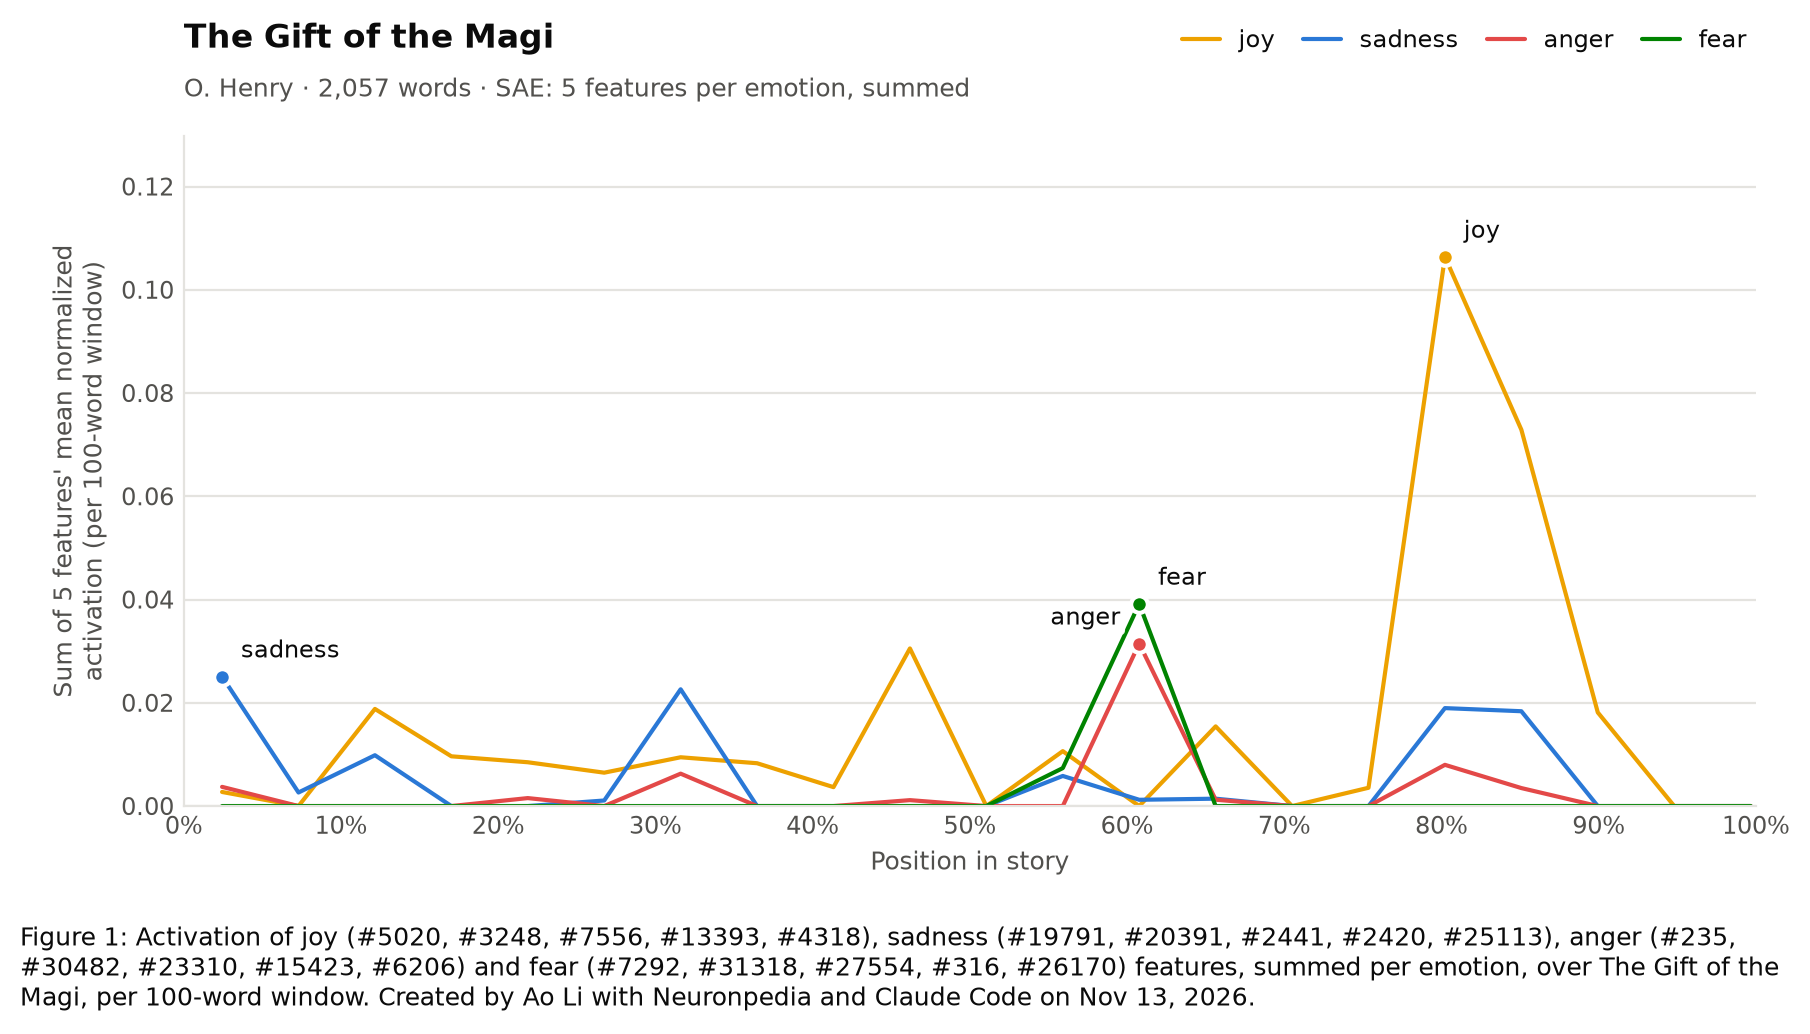

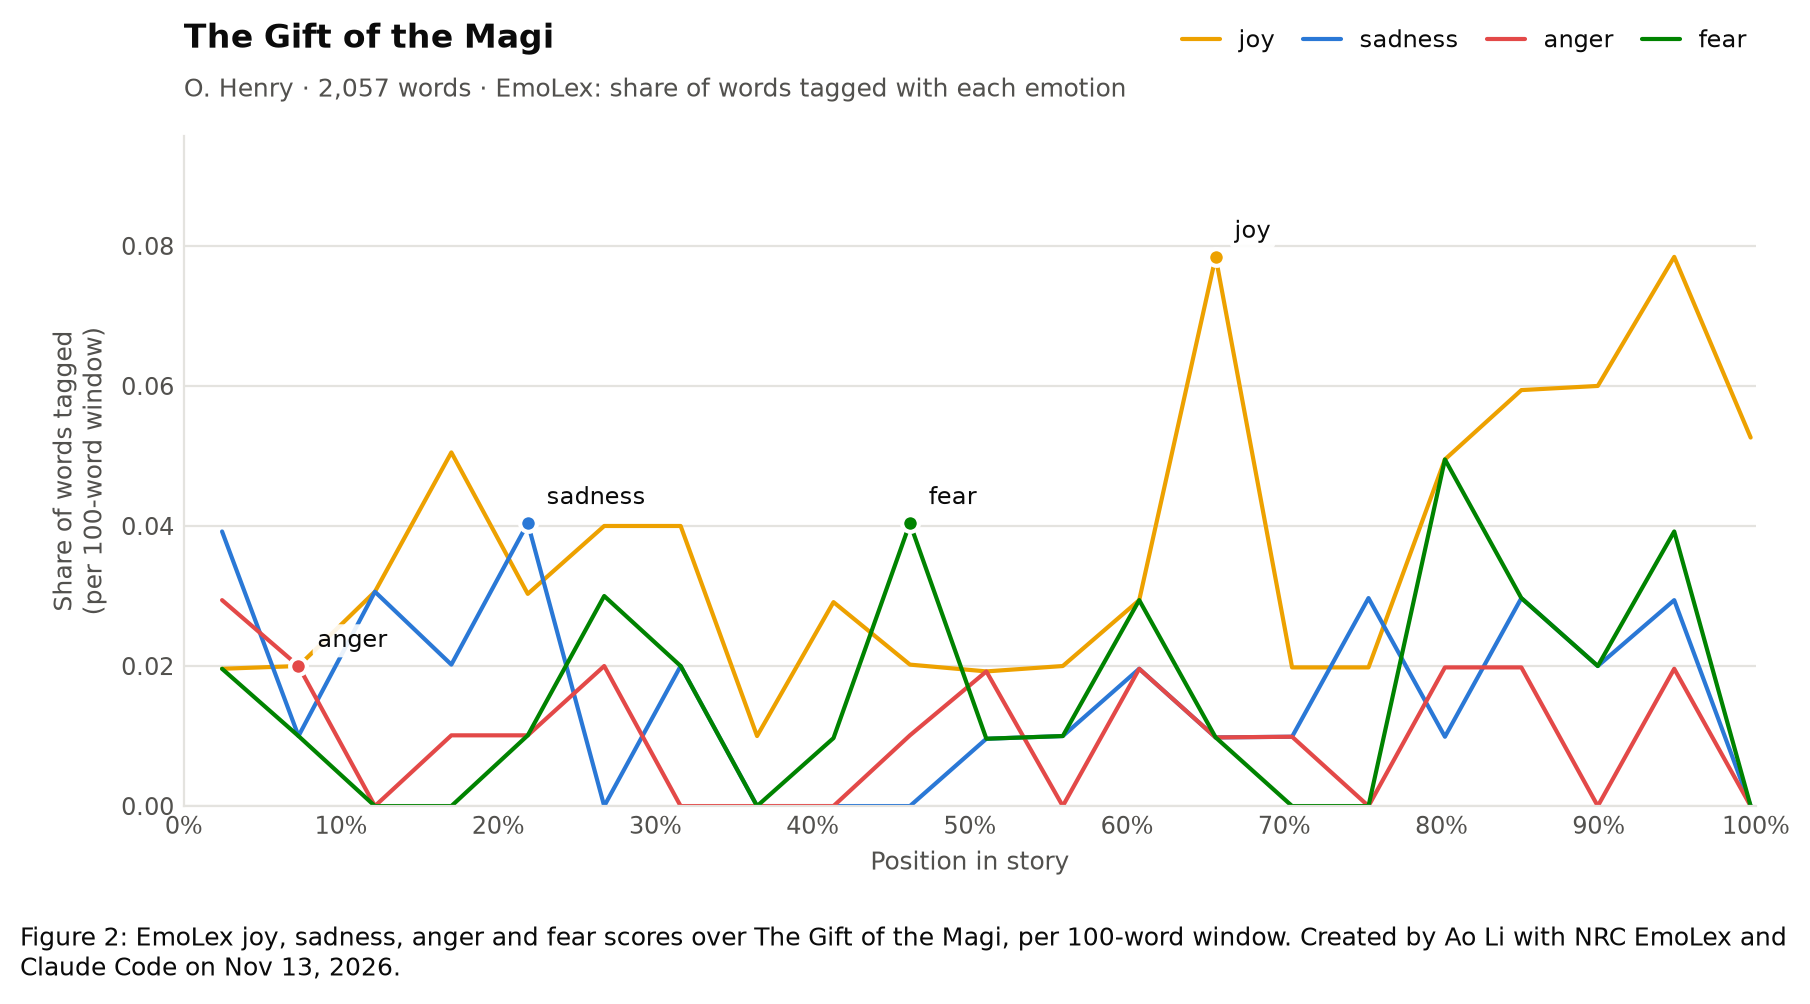

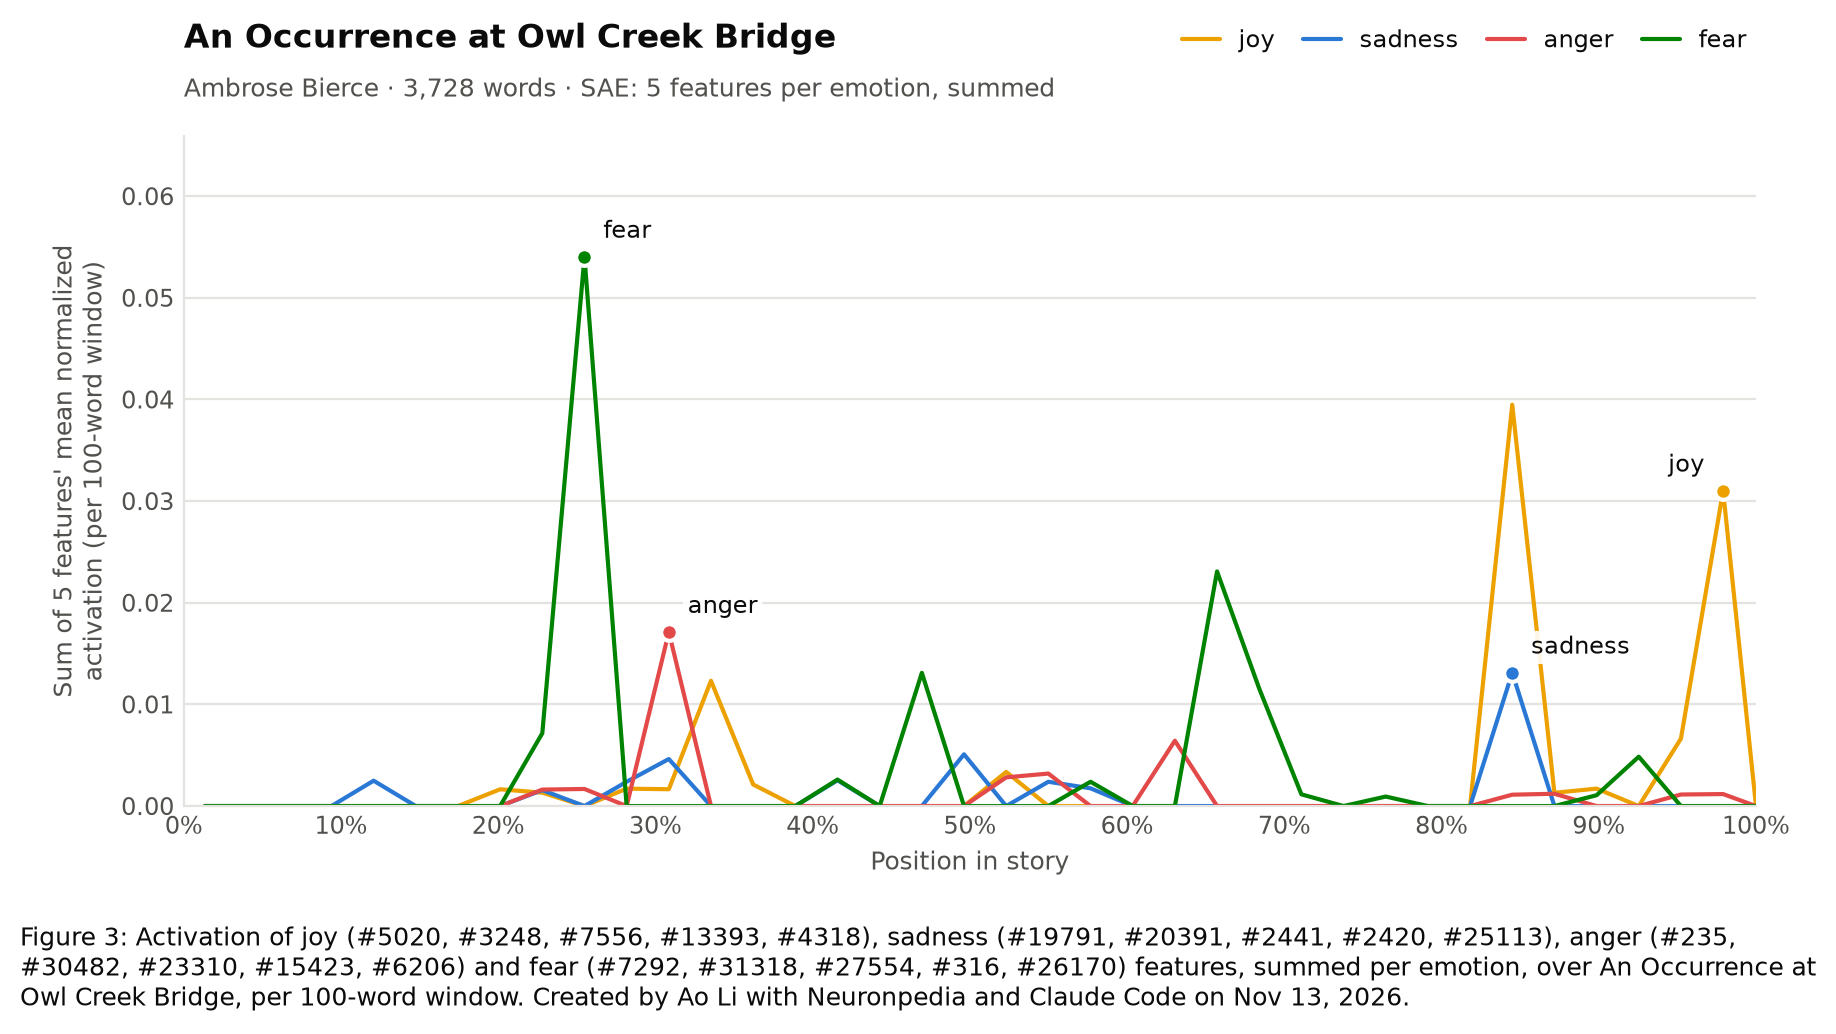

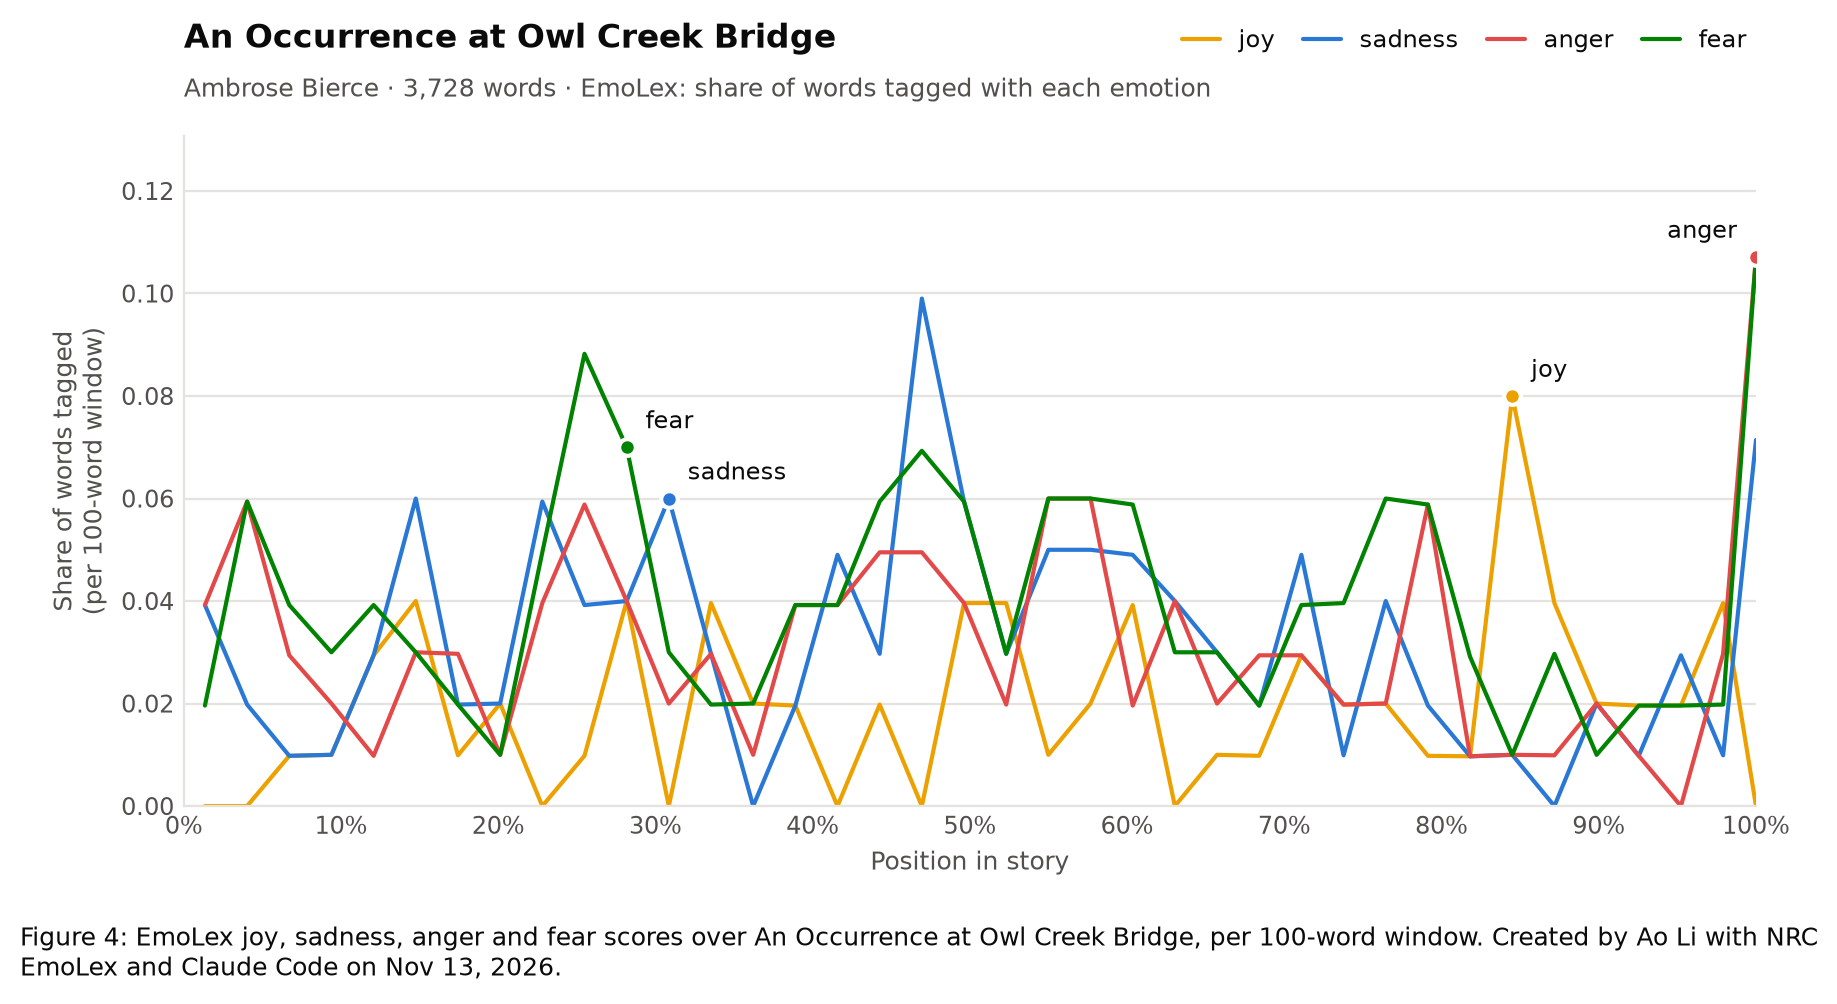

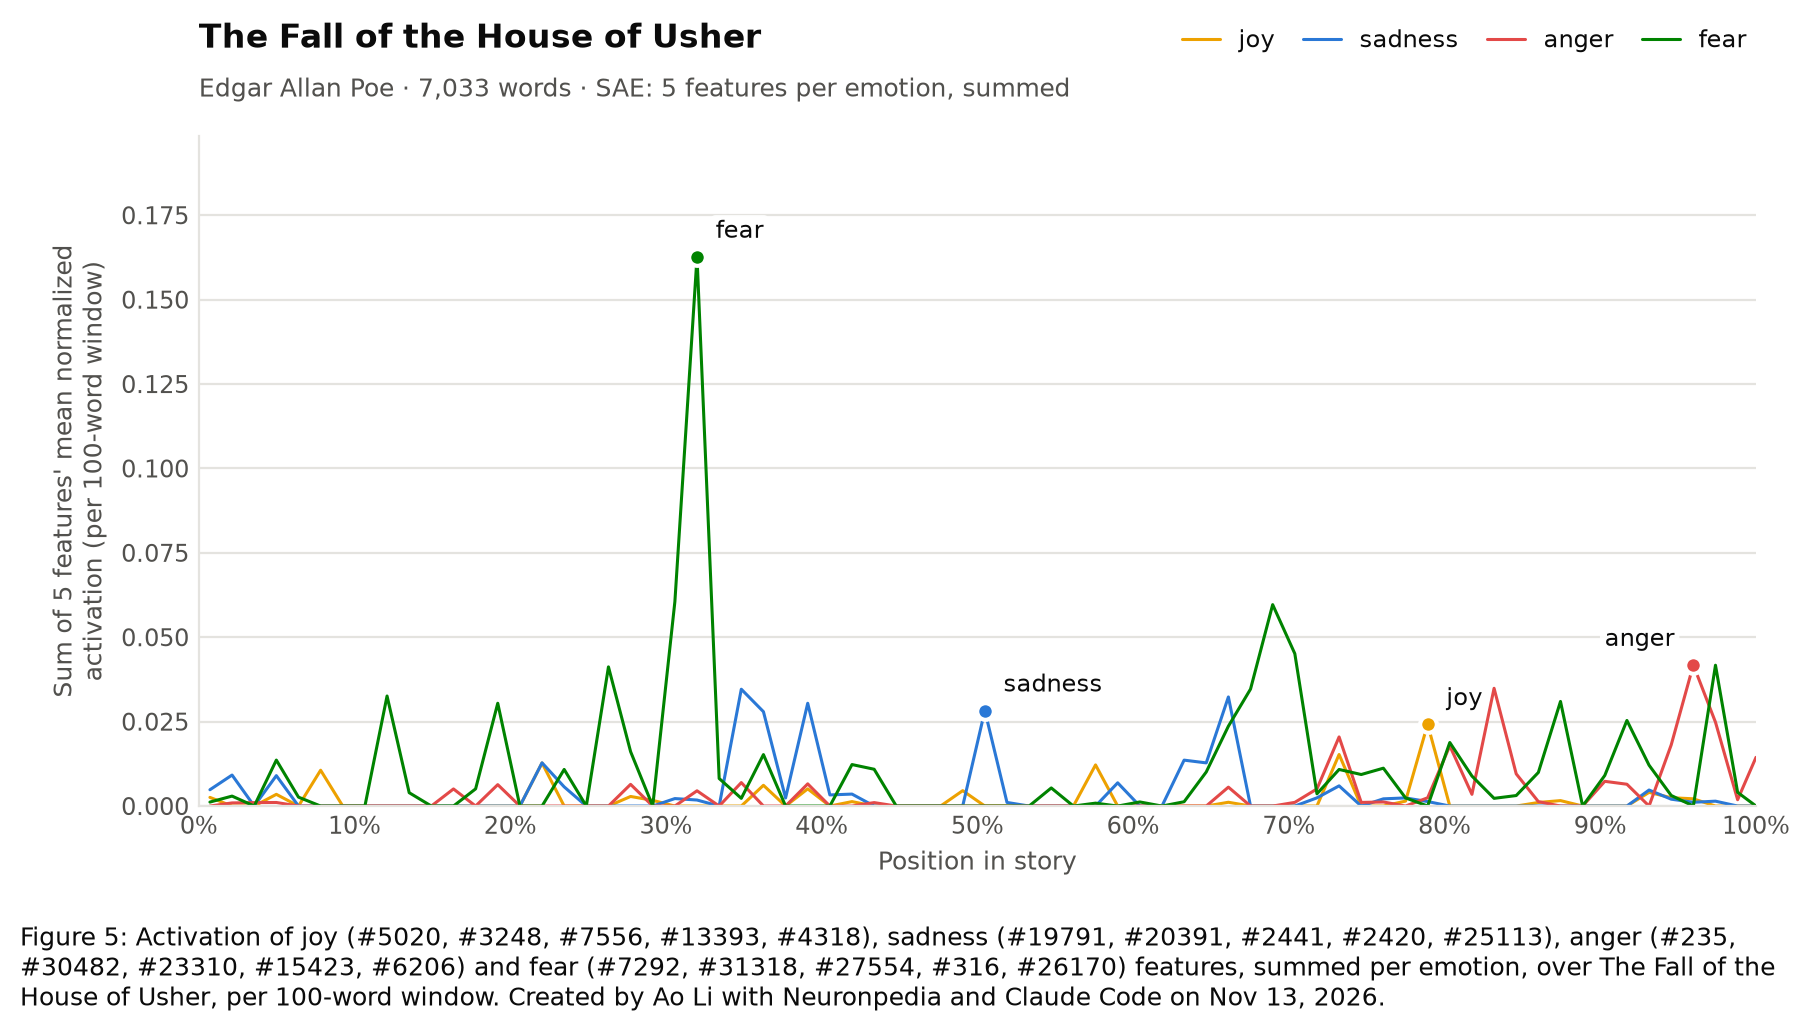

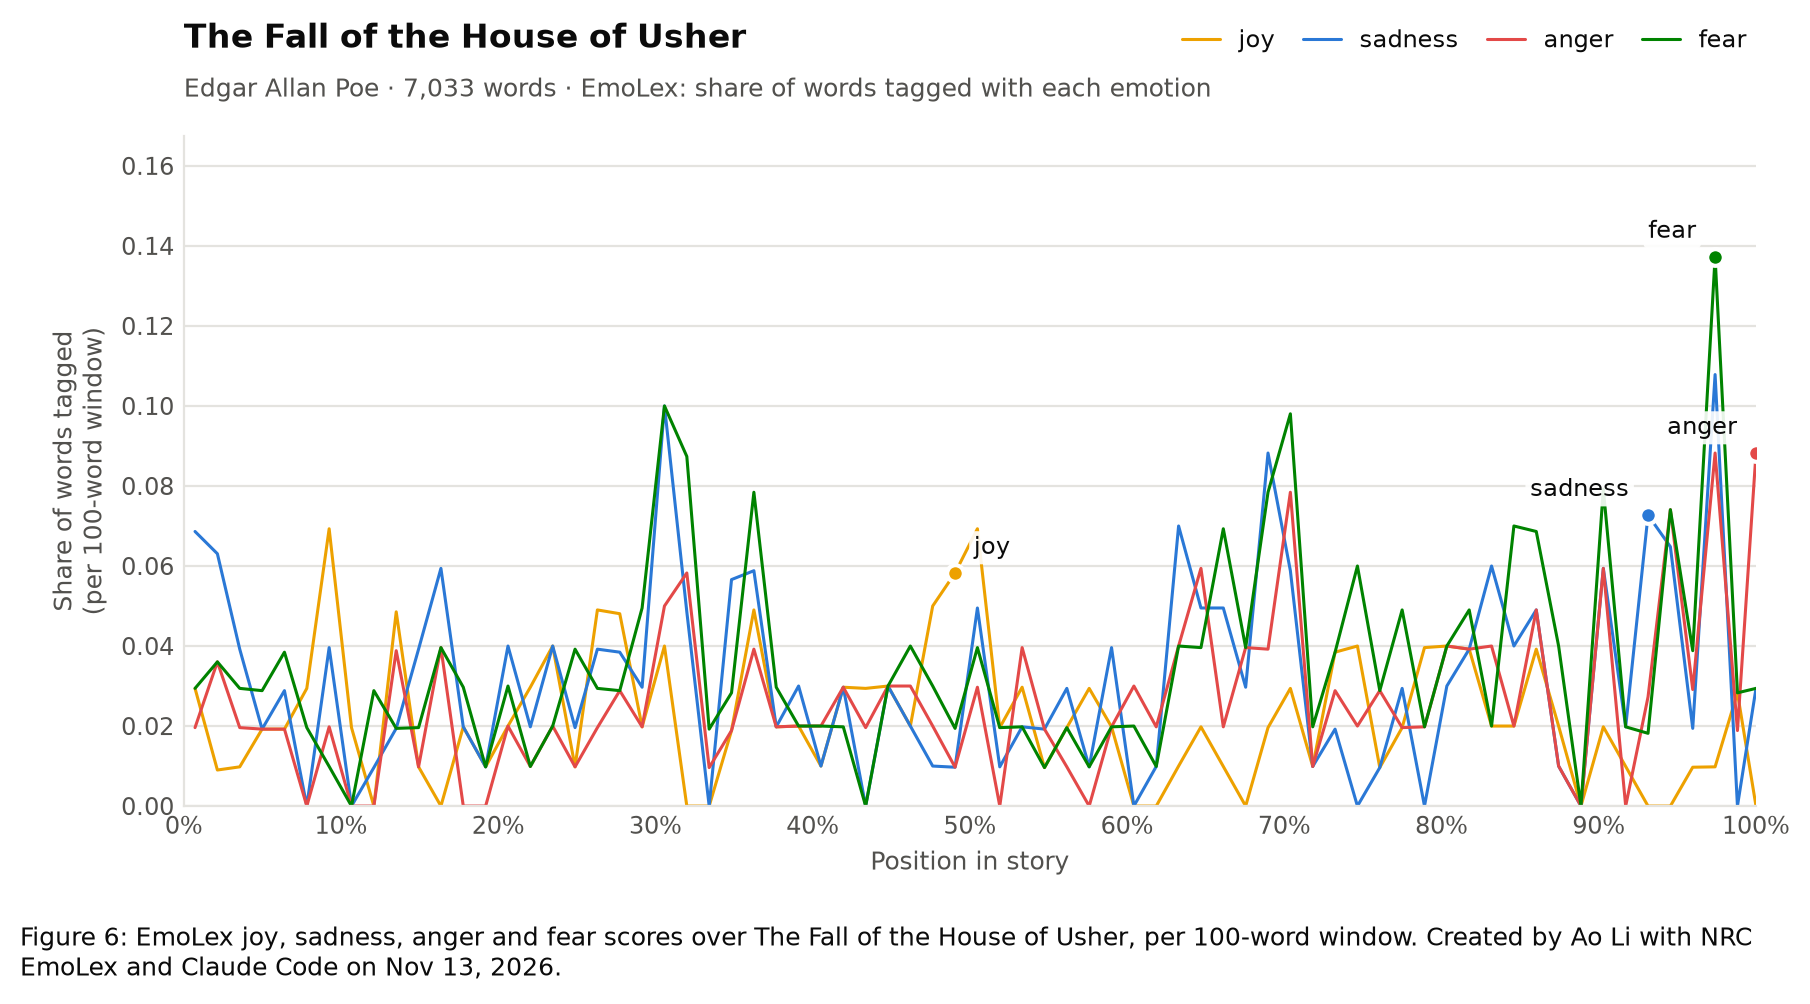

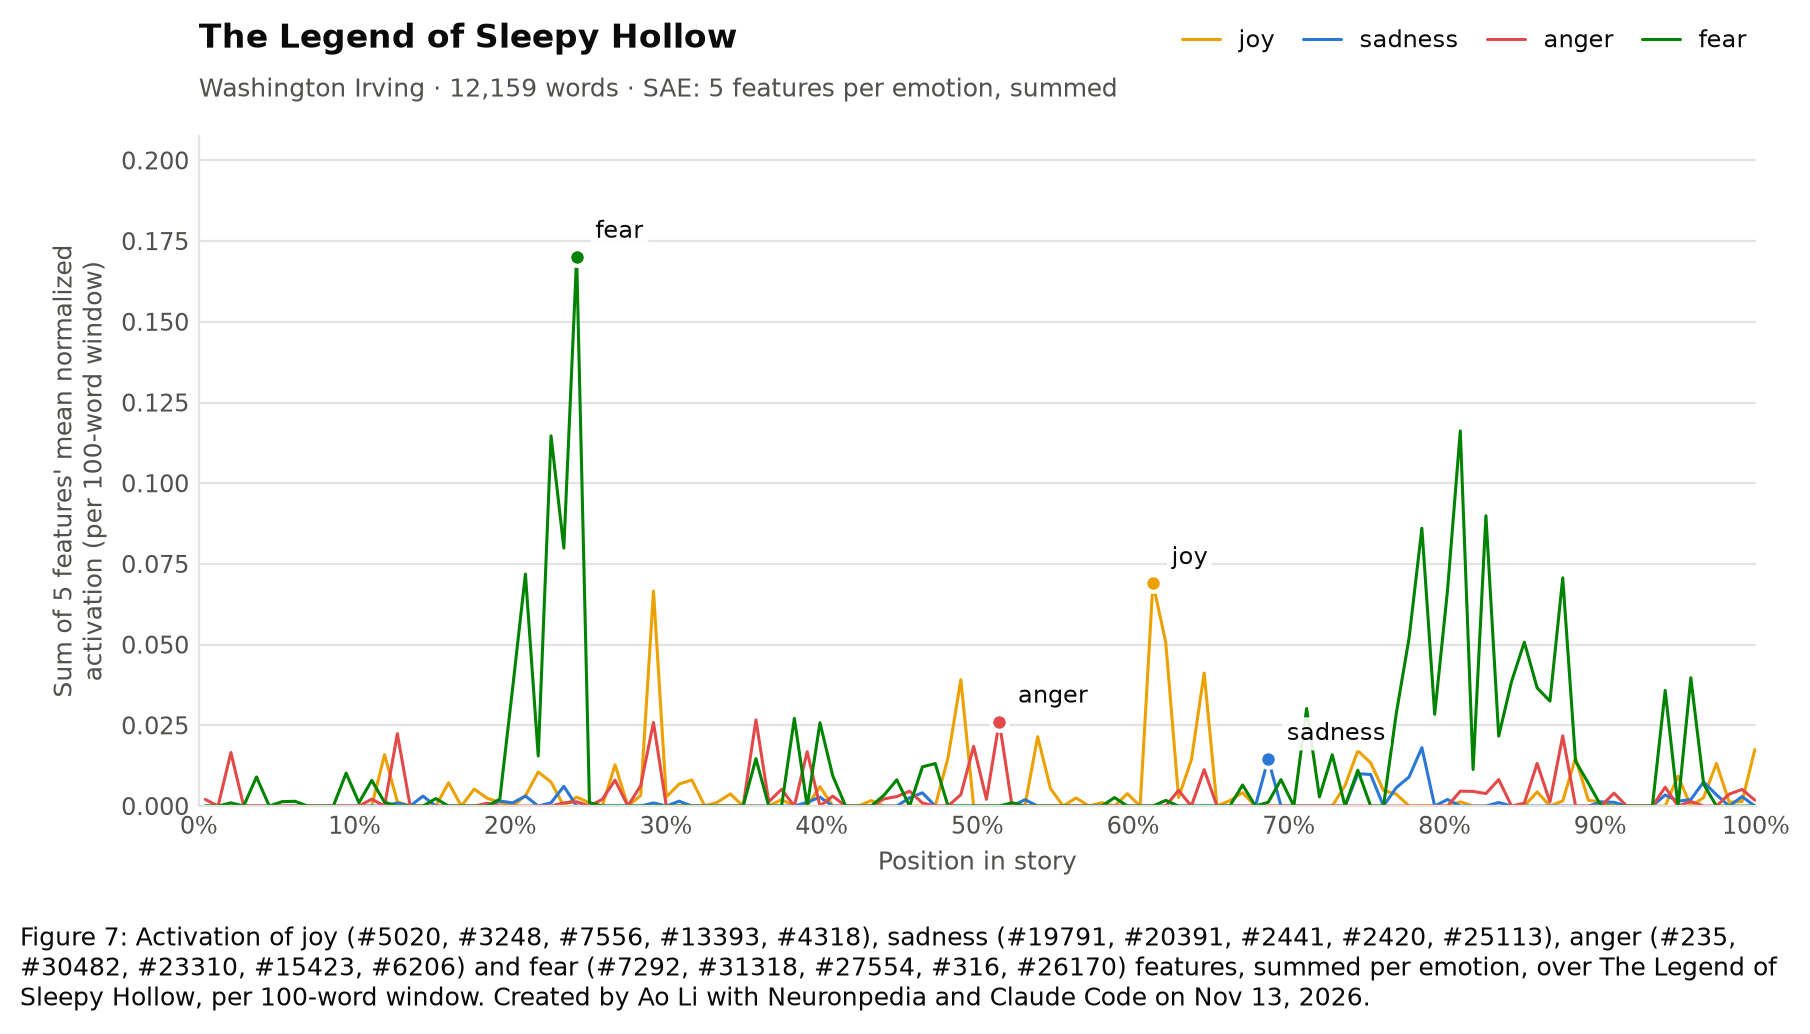

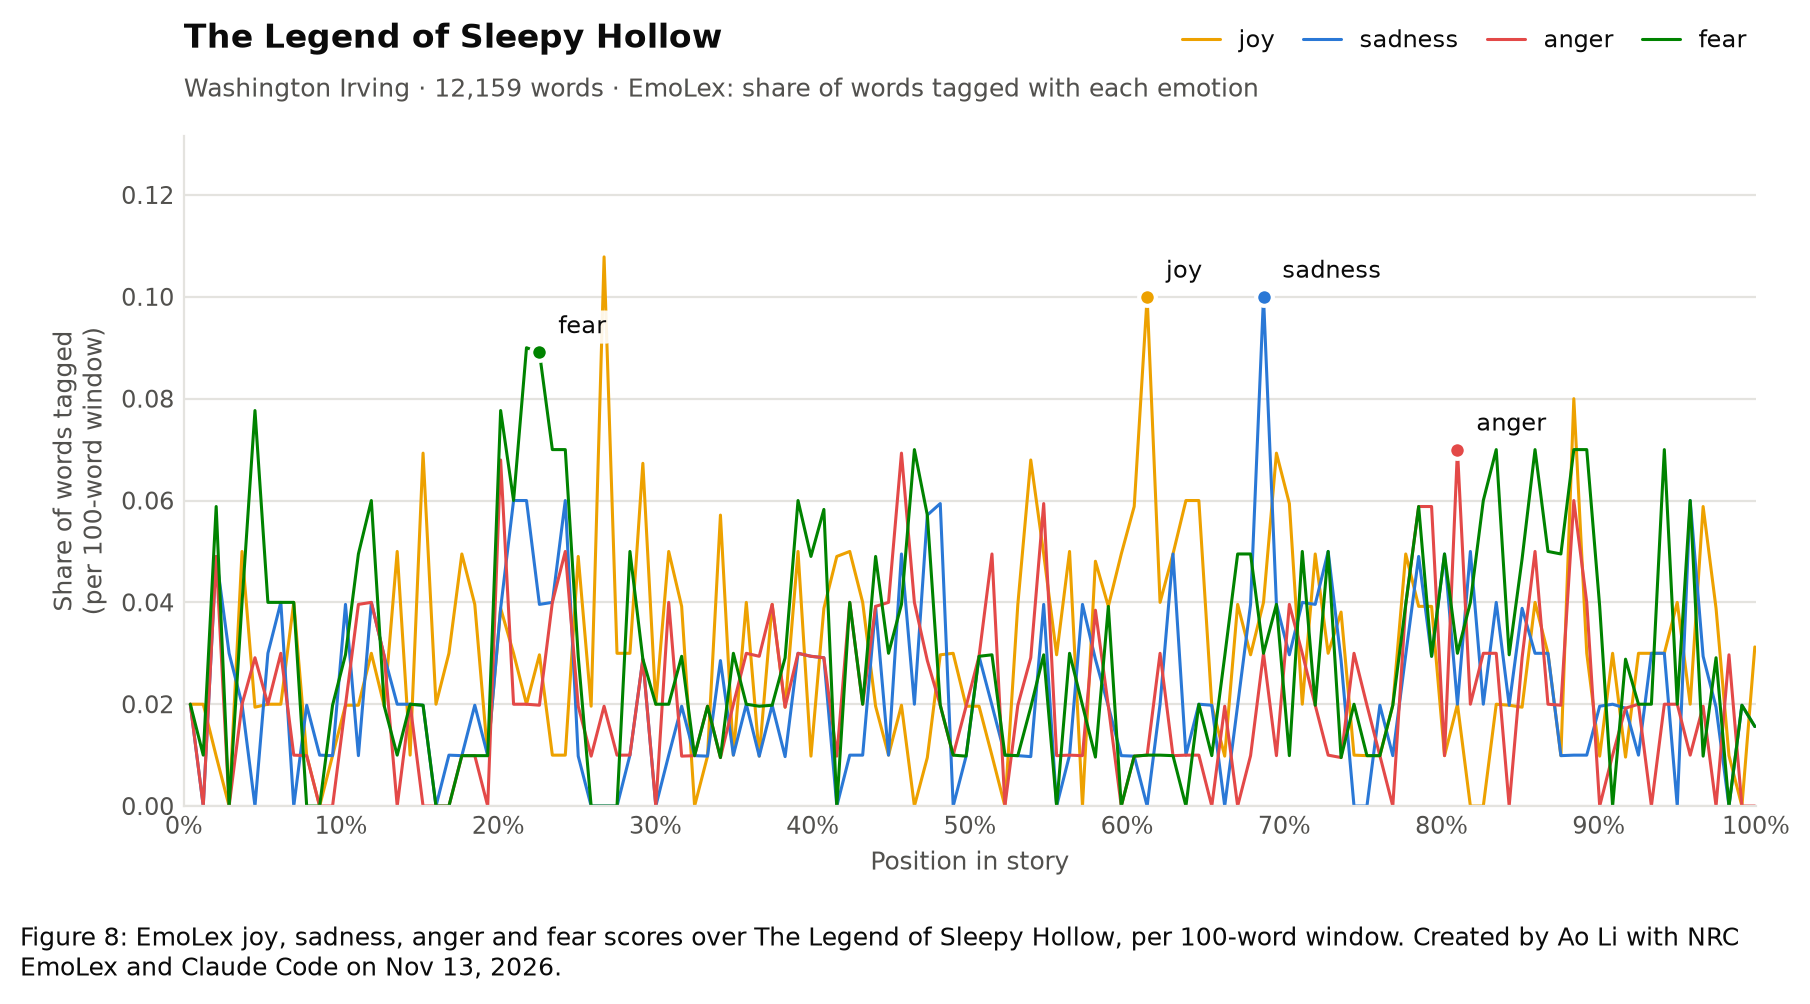

In [7]:
def feature_list(emotion: str) -> str:
    return f"{emotion} (" + ", ".join(f"#{index}" for _, index in FEATURES[emotion]) + ")"


sae_ids = ", ".join(feature_list(e) for e in EMOTIONS[:-1]) + f" and {feature_list(EMOTIONS[-1])}"
emotion_names = ", ".join(EMOTIONS[:-1]) + f" and {EMOTIONS[-1]}"

for n, s in enumerate(STORIES):
    r = results[s["title"]]
    sae_fig, emolex_fig = 2 * n + 1, 2 * n + 2
    plot_emotions(
        r["pcts"], r["sae"], s["title"],
        f"{s['author']} · {r['n_words']:,} words · SAE: 5 features per emotion, summed",
        f"Sum of 5 features' mean normalized\nactivation (per {WINDOW_WORDS}-word window)",
        f"Figure {sae_fig}: Activation of {sae_ids} features, summed per emotion, over {s['title']}, "
        f"per {WINDOW_WORDS}-word window. Created by Ao Li with Neuronpedia and Claude Code on {FIG_DATE}.",
        Path(f"figures/test3/figure{sae_fig}.png"),
    )
    plot_emotions(
        r["pcts"], r["emolex"], s["title"],
        f"{s['author']} · {r['n_words']:,} words · EmoLex: share of words tagged with each emotion",
        f"Share of words tagged\n(per {WINDOW_WORDS}-word window)",
        f"Figure {emolex_fig}: EmoLex {emotion_names} scores over {s['title']}, per {WINDOW_WORDS}-word window. "
        f"Created by Ao Li with NRC EmoLex and Claude Code on {FIG_DATE}.",
        Path(f"figures/test3/figure{emolex_fig}.png"),
    )